# 🏦 Bank Transaction Anomaly Detection — Statistical vs Machine-Learning Detectors

**Goal:** flag suspicious card transactions **without relying on fraud labels**, the way a bank's monitoring team has to when new fraud patterns appear before anyone has labelled them.

**Approach**
1. Generate a realistic, reproducible **simulated transaction stream** (1,000 customers × 60 days) with four injected fraud patterns: account takeover, card testing, impossible travel and risky-merchant spikes. Real bank data is confidential, so a documented simulator lets every assumption be inspected and changed.
2. Engineer **customer-relative behavioural features**: how unusual a transaction is *for that customer*, not just in absolute terms.
3. Compare **statistical detectors** (robust z-score / MAD, Mahalanobis distance with a χ² test from SciPy) with **machine-learning detectors** (Isolation Forest, Local Outlier Factor, One-Class SVM) and an ensemble.
4. Evaluate the way an operations team would, using **precision and recall at a fixed daily alert budget**, and break detection down by fraud type.

Labels are used **only for evaluation**, never for training.

*Author: Priyadharshini Sivasankar · MSc Data Science*

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import chi2, rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import MinCovDet
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

SEED = 7
rng = np.random.default_rng(SEED)
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True); os.makedirs("data", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
COL = {"Robust z-score (MAD)": "#94a3b8", "Mahalanobis (MCD + χ²)": "#2563eb", "Isolation Forest": "#16a34a",
       "Local Outlier Factor": "#f97316", "One-Class SVM": "#7c3aed", "Ensemble (rank average)": "#dc2626"}
print("Libraries loaded.")

Libraries loaded.


## 1. Simulate a realistic transaction stream
**Customers** each get a home city, a spending segment (log-normal amounts), daily activity level, active hours and a personal mix of merchant categories.

**Normal behaviour** includes legitimate surprises (occasional big purchases, travel to another city, late-night spending), so the detectors cannot simply flag "anything large".

**Injected fraud (about 0.45% of transactions)**
| Pattern | What it looks like |
|---|---|
| Account takeover | 4–15× the customer's usual amount, 00:00–05:00, in a city the customer never visits |
| Card testing | a burst of 4–8 tiny online payments (₹1–₹60) within minutes |
| Impossible travel | a transaction in another city a few minutes after one at home |
| Risky-merchant spike | a large payment at a gambling/crypto merchant the customer has never used |

In [2]:
CITIES = {"Chennai": (13.08, 80.27), "Bengaluru": (12.97, 77.59), "Mumbai": (19.08, 72.88), "Delhi": (28.61, 77.21),
          "Hyderabad": (17.39, 78.49), "Kolkata": (22.57, 88.36), "Pune": (18.52, 73.86), "Coimbatore": (11.02, 76.96),
          "Thanjavur": (10.79, 79.14), "Madurai": (9.93, 78.12), "Singapore": (1.35, 103.82), "Dubai": (25.20, 55.27)}
DOMESTIC = [c for c in CITIES if c not in ("Singapore", "Dubai")]
CATS = ["grocery", "fuel", "restaurant", "online_retail", "pharmacy", "utilities", "travel", "electronics", "entertainment", "gambling_crypto"]
BASE_MIX = np.array([.28, .12, .16, .18, .06, .06, .03, .04, .07, 0.0])
CAT_SCALE = {"grocery": .8, "fuel": 1.0, "restaurant": .7, "online_retail": 1.1, "pharmacy": .5, "utilities": 1.6,
             "travel": 4.0, "electronics": 5.0, "entertainment": .6, "gambling_crypto": 3.0}

N_CUST, N_DAYS = 1000, 60
START = pd.Timestamp("2026-07-01")
customers = pd.DataFrame({
    "customer_id": np.arange(N_CUST),
    "home_city": rng.choice(DOMESTIC, N_CUST),
    "segment_median_inr": np.exp(rng.normal(np.log(650), 0.6, N_CUST)).round(0),
    "tx_per_day": rng.gamma(2.0, 1.2, N_CUST).clip(.3, 8),
    "peak_hour": rng.normal(15, 3, N_CUST).clip(9, 21),
})
mixes = rng.dirichlet(BASE_MIX[:-1] * 25 + .3, N_CUST)

rows = []
for c in customers.itertuples():
    n = rng.poisson(c.tx_per_day * N_DAYS)
    days = rng.integers(0, N_DAYS, n)
    hours = (rng.normal(c.peak_hour, 3.5, n) % 24)
    t = START + pd.to_timedelta(days, "D") + pd.to_timedelta(hours, "h")
    cats = rng.choice(CATS[:-1], n, p=mixes[c.customer_id])
    amt = np.array([np.exp(rng.normal(np.log(c.segment_median_inr * CAT_SCALE[k]), 0.55)) for k in cats])
    big = rng.random(n) < .01; amt[big] *= rng.uniform(3, 8, big.sum())          # legitimate big purchases
    city = np.where(rng.random(n) < .03, rng.choice(DOMESTIC, n), c.home_city)   # legitimate trips
    rows.append(pd.DataFrame({"customer_id": c.customer_id, "timestamp": t, "amount_inr": amt.round(2),
                              "merchant_category": cats, "city": city, "channel": np.where(np.isin(cats, ["online_retail", "utilities"]), "online", "pos"),
                              "fraud_type": "normal"}))
tx = pd.concat(rows, ignore_index=True)
print(f"Normal transactions simulated: {len(tx):,}")

Normal transactions simulated: 142,701


In [3]:
def inject(tx):
    frauds = []
    victims = rng.choice(N_CUST, 260, replace=False)
    kinds = np.array(["account_takeover", "card_testing", "impossible_travel", "risky_merchant"])[rng.integers(0, 4, len(victims))]
    for cid, kind in zip(victims, kinds):
        prof = customers.loc[cid]; hist = tx[tx.customer_id == cid]
        day = START + pd.Timedelta(days=int(rng.integers(2, N_DAYS)))
        if kind == "account_takeover":
            far = rng.choice([x for x in CITIES if x != prof.home_city])
            for _ in range(rng.integers(1, 4)):
                frauds.append([cid, day + pd.Timedelta(hours=float(rng.uniform(0, 5))), prof.segment_median_inr * rng.uniform(4, 15),
                               rng.choice(["electronics", "online_retail", "travel"]), far, "online", kind])
        elif kind == "card_testing":
            t0 = day + pd.Timedelta(hours=float(rng.uniform(0, 24)))
            for k in range(rng.integers(4, 9)):
                frauds.append([cid, t0 + pd.Timedelta(minutes=float(k * rng.uniform(.5, 3))), rng.uniform(1, 60),
                               "online_retail", prof.home_city, "online", kind])
        elif kind == "impossible_travel":
            t0 = day + pd.Timedelta(hours=float(rng.uniform(8, 20)))
            far = rng.choice([x for x in CITIES if x != prof.home_city])
            frauds.append([cid, t0, prof.segment_median_inr * rng.uniform(.6, 1.5), "grocery", prof.home_city, "pos", "normal"])  # genuine
            frauds.append([cid, t0 + pd.Timedelta(minutes=float(rng.uniform(5, 40))), prof.segment_median_inr * rng.uniform(1.5, 5),
                           rng.choice(["electronics", "restaurant", "online_retail"]), far, "pos", kind])
        else:
            frauds.append([cid, day + pd.Timedelta(hours=float(rng.uniform(0, 24))), prof.segment_median_inr * rng.uniform(5, 20),
                           "gambling_crypto", prof.home_city, "online", kind])
    f = pd.DataFrame(frauds, columns=tx.columns)
    f["amount_inr"] = f.amount_inr.astype(float).round(2)
    return pd.concat([tx, f], ignore_index=True).sort_values(["customer_id", "timestamp"]).reset_index(drop=True)

tx = inject(tx)
tx["is_fraud"] = (tx.fraud_type != "normal").astype(int)
print(f"Total transactions: {len(tx):,} | fraudulent: {tx.is_fraud.sum()} ({tx.is_fraud.mean():.2%})")
display(tx.fraud_type.value_counts().to_frame("count"))
tx.to_csv("data/simulated_transactions.csv.gz", index=False, compression="gzip")
display(tx.sample(6, random_state=1))

Total transactions: 143,420 | fraudulent: 649 (0.45%)


,count
fraud_type,
normal,142771
card_testing,389
account_takeover,122
impossible_travel,70
risky_merchant,68


,customer_id,timestamp,amount_inr,merchant_category,city,channel,fraud_type,is_fraud
96622,669,2026-08-20 13:36:02.573901579,536.38,grocery,Madurai,pos,normal,0
116490,804,2026-08-17 12:47:57.422119192,268.87,restaurant,Kolkata,pos,normal,0
121784,843,2026-07-07 20:15:54.263380600,854.54,pharmacy,Coimbatore,pos,normal,0
75663,517,2026-08-14 09:13:21.131213386,618.59,grocery,Kolkata,pos,normal,0
127868,882,2026-08-24 18:44:50.146430992,1138.66,grocery,Delhi,pos,normal,0
81948,561,2026-07-06 22:42:56.152261440,1107.40,utilities,Pune,online,normal,0


## 2. Feature engineering: behaviour relative to each customer
A ₹20,000 payment is normal for one customer and alarming for another. Each customer's **baseline** (median and MAD of amount, usual hours, home city, category mix) is learned from the **first 30 days only**. The detectors then score days 31–60, which mimics deploying the model on new data.

In [4]:
tx = tx.sort_values(["customer_id", "timestamp"]).reset_index(drop=True)
SPLIT = START + pd.Timedelta(days=30)
base = tx[tx.timestamp < SPLIT]

def haversine(a, b):
    (la1, lo1), (la2, lo2) = np.radians(a).T, np.radians(b).T
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(h))

prof = base.groupby("customer_id").agg(med_amt=("amount_inr", "median"),
                                       mad_amt=("amount_inr", lambda s: stats.median_abs_deviation(np.log1p(s), scale="normal")),
                                       med_log=("amount_inr", lambda s: np.median(np.log1p(s))),
                                       med_hour=("timestamp", lambda s: np.median(s.dt.hour + s.dt.minute / 60)))
cat_share = base.groupby(["customer_id", "merchant_category"]).size().div(base.groupby("customer_id").size(), level=0).rename("cat_share")
home = customers.set_index("customer_id").home_city

f = tx.join(prof, on="customer_id")
f["log_amount"] = np.log1p(f.amount_inr)
f["amount_robust_z"] = (f.log_amount - f.med_log) / f.mad_amt.clip(lower=.1)
hour = f.timestamp.dt.hour + f.timestamp.dt.minute / 60
f["hour_sin"], f["hour_cos"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
f["hours_from_usual"] = np.minimum(abs(hour - f.med_hour), 24 - abs(hour - f.med_hour))
coords = np.array([CITIES[c] for c in f.city]); homec = np.array([CITIES[c] for c in f.customer_id.map(home)])
f["km_from_home"] = haversine(coords, homec)
f["log_km_from_home"] = np.log1p(f.km_from_home)
f = f.join(cat_share, on=["customer_id", "merchant_category"])
f["category_rarity"] = 1 - f.cat_share.fillna(0)
g = f.groupby("customer_id")
f["mins_since_prev"] = g.timestamp.diff().dt.total_seconds().div(60).fillna(24 * 60).clip(upper=24 * 60)
prev_coords = np.vstack([np.roll(coords, 1, axis=0)]); prev_coords[f.customer_id.ne(f.customer_id.shift()).values] = coords[f.customer_id.ne(f.customer_id.shift()).values]
f["speed_kmh"] = (haversine(coords, prev_coords) / (f.mins_since_prev.clip(lower=1) / 60)).clip(upper=5000)
f["log_speed"] = np.log1p(f.speed_kmh)
f["tx_last_hour"] = (f.set_index("timestamp").groupby("customer_id").amount_inr.rolling("60min").count().values)
f["log_mins_since_prev"] = np.log1p(f.mins_since_prev)

FEATURES = ["amount_robust_z", "log_amount", "hour_sin", "hour_cos", "hours_from_usual", "log_km_from_home",
            "category_rarity", "log_mins_since_prev", "log_speed", "tx_last_hour"]
train = f[f.timestamp < SPLIT].copy(); test = f[f.timestamp >= SPLIT].copy()
print(f"Train (days 1-30): {len(train):,} tx, fraud {train.is_fraud.mean():.2%} (unlabelled in practice)")
print(f"Test  (days 31-60): {len(test):,} tx, fraud {test.is_fraud.sum()} ({test.is_fraud.mean():.2%})")
display(test.groupby("fraud_type")[FEATURES].median().round(2))

Train (days 1-30): 71,808 tx, fraud 0.48% (unlabelled in practice)
Test  (days 31-60): 71,612 tx, fraud 305 (0.43%)


,amount_robust_z,log_amount,hour_sin,hour_cos,hours_from_usual,log_km_from_home,category_rarity,log_mins_since_prev,log_speed,tx_last_hour
fraud_type,,,,,,,,,,
account_takeover,3.31,8.70,0.70,0.71,9.92,7.07,0.96,5.29,2.40,1.0
card_testing,-4.44,3.51,0.30,-0.12,5.51,0.00,0.86,1.14,0.00,3.5
impossible_travel,1.94,7.43,-0.79,-0.61,2.56,6.66,0.84,3.25,7.67,2.0
normal,0.01,6.39,-0.54,-0.56,2.40,0.00,0.83,5.26,0.00,1.0
risky_merchant,4.12,8.98,-0.13,-0.10,5.44,0.00,1.00,6.35,0.00,1.0


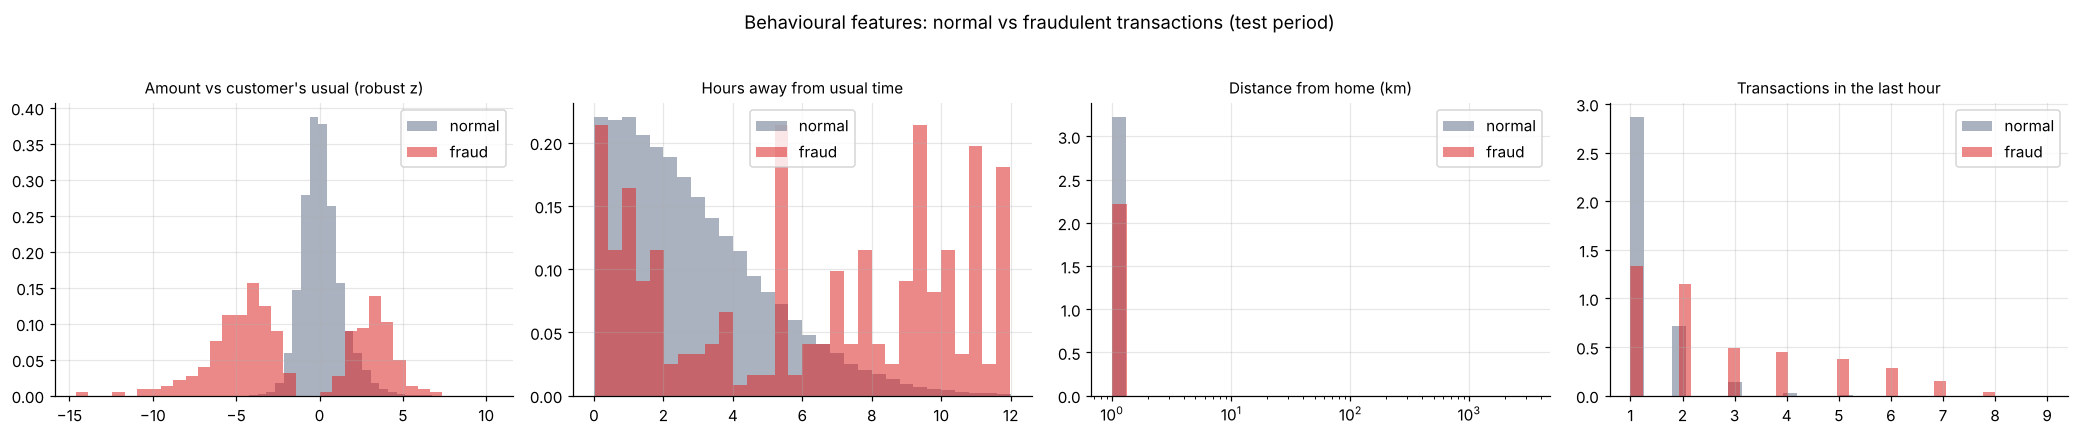

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
for ax, feat, title, log in [(axes[0], "amount_robust_z", "Amount vs customer's usual (robust z)", False),
                             (axes[1], "hours_from_usual", "Hours away from usual time", False),
                             (axes[2], "km_from_home", "Distance from home (km)", True),
                             (axes[3], "tx_last_hour", "Transactions in the last hour", False)]:
    for lab, colr, name in [(0, "#64748b", "normal"), (1, "#dc2626", "fraud")]:
        v = test.loc[test.is_fraud == lab, feat]
        bins = np.logspace(0, np.log10(v.max() + 2), 30) if log else 30
        ax.hist(v + (1 if log else 0), bins=bins, density=True, alpha=.55, color=colr, label=name)
    if log: ax.set_xscale("log")
    ax.set_title(title, fontsize=10); ax.legend()
plt.suptitle("Behavioural features: normal vs fraudulent transactions (test period)", y=1.03)
plt.tight_layout(); plt.savefig("figures/feature_distributions.png", bbox_inches="tight"); plt.show()

## 3. Detectors
Every detector is fitted on the **unlabelled** days 1–30 (which, realistically, already contain some fraud) and outputs an **anomaly score** for days 31–60, where a higher score means more suspicious.

| Detector | Idea | Library |
|---|---|---|
| Robust z-score (MAD) | how many robust standard deviations the amount is from the customer's median | SciPy |
| Mahalanobis + χ² | distance from the centre of normal behaviour under a *robust* covariance (Minimum Covariance Determinant); squared distance ~ χ²(p) gives a p-value | scikit-learn + SciPy |
| Isolation Forest | anomalies are isolated in fewer random splits | scikit-learn |
| Local Outlier Factor | anomalies sit in regions of lower local density than their neighbours | scikit-learn |
| One-Class SVM | learns a boundary around normal data with an RBF kernel | scikit-learn |
| Ensemble | average of the percentile ranks of the four multivariate detectors | NumPy / SciPy |

In [6]:
scaler = StandardScaler().fit(train[FEATURES])
Xtr, Xte = scaler.transform(train[FEATURES]), scaler.transform(test[FEATURES])
scores = {}

scores["Robust z-score (MAD)"] = test.amount_robust_z.abs().values

mcd = MinCovDet(random_state=SEED, support_fraction=.9).fit(Xtr[rng.choice(len(Xtr), 15000, replace=False)])
d2 = mcd.mahalanobis(Xte)
scores["Mahalanobis (MCD + χ²)"] = d2
pvals = chi2.sf(d2, df=len(FEATURES))
print(f"Mahalanobis: {np.mean(pvals < 0.001):.2%} of test transactions have chi-square p < 0.001")

iso = IsolationForest(n_estimators=400, contamination="auto", random_state=SEED, n_jobs=-1).fit(Xtr)
scores["Isolation Forest"] = -iso.score_samples(Xte)

lof = LocalOutlierFactor(n_neighbors=50, novelty=True, n_jobs=-1).fit(Xtr[rng.choice(len(Xtr), 20000, replace=False)])
scores["Local Outlier Factor"] = -lof.score_samples(Xte)

ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.01).fit(Xtr[rng.choice(len(Xtr), 8000, replace=False)])
scores["One-Class SVM"] = -ocsvm.score_samples(Xte)

multi = ["Mahalanobis (MCD + χ²)", "Isolation Forest", "Local Outlier Factor", "One-Class SVM"]
scores["Ensemble (rank average)"] = np.mean([rankdata(scores[m]) / len(Xte) for m in multi], axis=0)
print("All detectors scored", len(Xte), "test transactions.")

Mahalanobis: 6.08% of test transactions have chi-square p < 0.001
All detectors scored 71612 test transactions.


## 4. Evaluation as an operations team sees it
A fraud team can only review a limited number of alerts each day. Besides ROC-AUC and PR-AUC (average precision), we report **precision and recall when the team reviews the top 0.5% and top 1% most suspicious transactions**.

In [7]:
y = test.is_fraud.values
def at_budget(s, frac):
    k = int(round(frac * len(s))); top = np.argsort(-s)[:k]
    tp = y[top].sum(); return tp / k, tp / y.sum(), k
rows = []
for name, s in scores.items():
    p05, r05, k05 = at_budget(s, .005); p1, r1, k1 = at_budget(s, .01)
    rows.append({"detector": name, "ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
                 "precision@0.5%": p05, "recall@0.5%": r05, "precision@1%": p1, "recall@1%": r1})
evaluation = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
print(f"Alert budgets: top 0.5% = {k05} alerts, top 1% = {k1} alerts, over 30 days | fraud in test = {y.sum()} | random PR-AUC baseline = {y.mean():.4f}")
display(evaluation.round(3))
evaluation.to_csv("results/detector_comparison.csv", index=False)

Alert budgets: top 0.5% = 358 alerts, top 1% = 716 alerts, over 30 days | fraud in test = 305 | random PR-AUC baseline = 0.0043


,detector,ROC-AUC,PR-AUC,precision@0.5%,recall@0.5%,precision@1%,recall@1%
0,Ensemble (rank average),0.986,0.596,0.584,0.685,0.337,0.790
1,Isolation Forest,0.985,0.458,0.430,0.505,0.284,0.666
2,One-Class SVM,0.964,0.427,0.425,0.498,0.286,0.672
3,Local Outlier Factor,0.959,0.324,0.380,0.446,0.268,0.630
4,Robust z-score (MAD),0.973,0.323,0.338,0.397,0.230,0.541
5,Mahalanobis (MCD + χ²),0.964,0.072,0.075,0.089,0.057,0.134


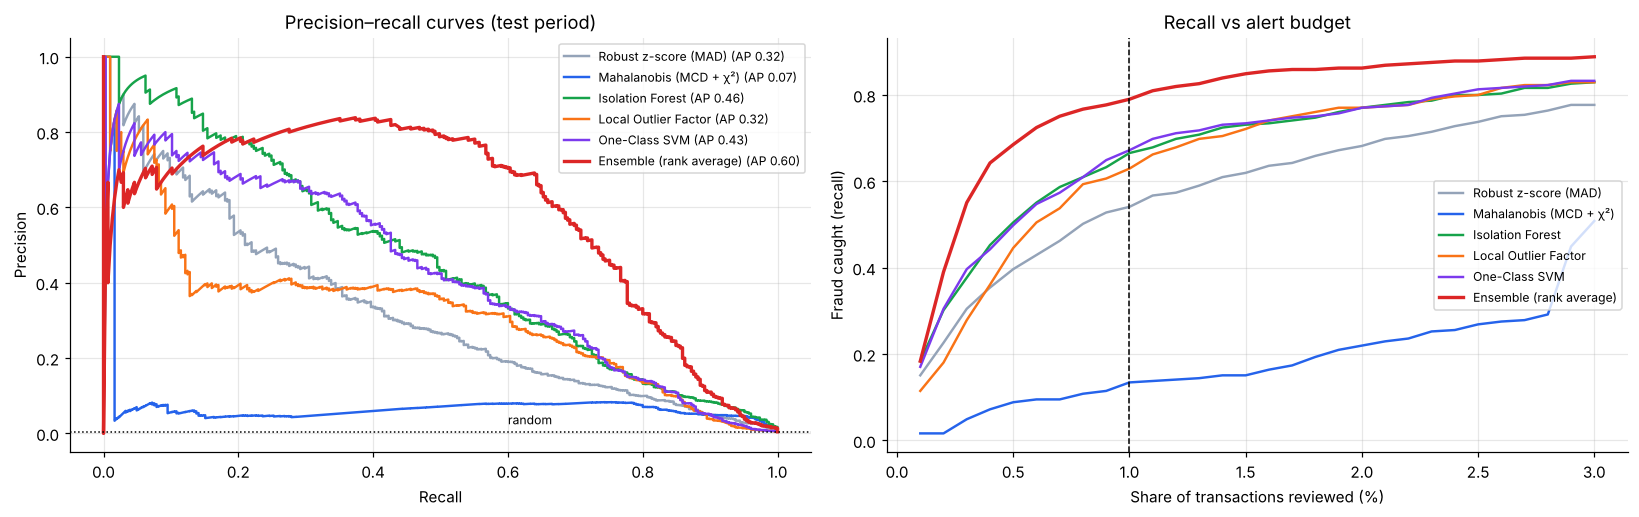

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for name, s in scores.items():
    p, r, _ = precision_recall_curve(y, s)
    axes[0].plot(r, p, color=COL[name], lw=2.2 if "Ensemble" in name else 1.6, label=f"{name} (AP {average_precision_score(y, s):.2f})")
axes[0].axhline(y.mean(), color="k", ls=":", lw=1); axes[0].text(.6, y.mean() + .02, "random", fontsize=8)
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Precision–recall curves (test period)"); axes[0].legend(fontsize=8)
budgets = np.linspace(.001, .03, 30)
for name, s in scores.items():
    axes[1].plot(budgets * 100, [at_budget(s, b)[1] for b in budgets], color=COL[name], lw=2.2 if "Ensemble" in name else 1.6, label=name)
axes[1].axvline(1, color="k", ls="--", lw=1)
axes[1].set_xlabel("Share of transactions reviewed (%)"); axes[1].set_ylabel("Fraud caught (recall)"); axes[1].set_title("Recall vs alert budget"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/pr_curves_and_budget.png", bbox_inches="tight"); plt.show()

### Which fraud patterns does each detector catch?
Recall at the 1% alert budget, broken down by fraud type. This shows the detectors are **complementary**, which is the reason for the ensemble.

,account_takeover,card_testing,impossible_travel,risky_merchant
Robust z-score (MAD),0.316,0.683,0.000,0.667
Mahalanobis (MCD + χ²),0.509,0.000,0.375,0.000
Isolation Forest,0.965,0.624,0.969,0.033
Local Outlier Factor,0.561,0.817,0.000,0.267
One-Class SVM,0.719,0.769,0.250,0.433
Ensemble (rank average),0.965,0.892,0.219,0.433


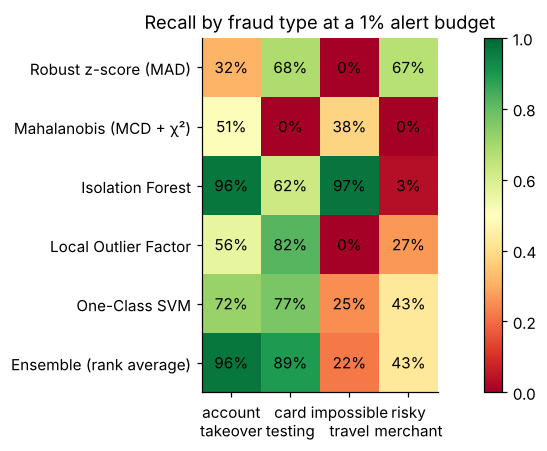

In [9]:
types = ["account_takeover", "card_testing", "impossible_travel", "risky_merchant"]
mat = []
for name, s in scores.items():
    k = int(round(.01 * len(s))); flagged = np.zeros(len(s), bool); flagged[np.argsort(-s)[:k]] = True
    mat.append([flagged[test.fraud_type.values == t].mean() for t in types])
mat = pd.DataFrame(mat, index=list(scores), columns=types)
fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(mat.values, cmap="RdYlGn", vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(len(types))); ax.set_xticklabels([t.replace("_", "\n") for t in types]); ax.set_yticks(range(len(mat))); ax.set_yticklabels(mat.index)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]): ax.text(j, i, f"{mat.iloc[i, j]:.0%}", ha="center", va="center", fontsize=10)
plt.colorbar(im, fraction=.03); ax.set_title("Recall by fraud type at a 1% alert budget")
plt.tight_layout(); plt.savefig("figures/recall_by_fraud_type.png", bbox_inches="tight"); plt.show()
mat.to_csv("results/recall_by_fraud_type.csv")
display(mat.round(3))

### Statistical significance: is the best detector really better than Isolation Forest?
A **paired bootstrap** (1,000 resamples of the test period, using NumPy) gives a 95% confidence interval for the difference in PR-AUC.

In [10]:
best = evaluation.detector.iloc[0]
other = "Isolation Forest" if best != "Isolation Forest" else evaluation.detector.iloc[1]
diffs = []
idx_all = np.arange(len(y))
for _ in range(1000):
    i = rng.choice(idx_all, len(idx_all), replace=True)
    if y[i].sum() == 0: continue
    diffs.append(average_precision_score(y[i], scores[best][i]) - average_precision_score(y[i], scores[other][i]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"PR-AUC difference ({best} − {other}): {np.mean(diffs):+.3f}, 95% CI [{lo:+.3f}, {hi:+.3f}]")
print("-> significant (CI excludes 0)" if lo > 0 or hi < 0 else "-> not significant (CI includes 0)")

PR-AUC difference (Ensemble (rank average) − Isolation Forest): +0.141, 95% CI [+0.079, +0.194]
-> significant (CI excludes 0)


## 5. Visualising the anomalies (PCA projection)

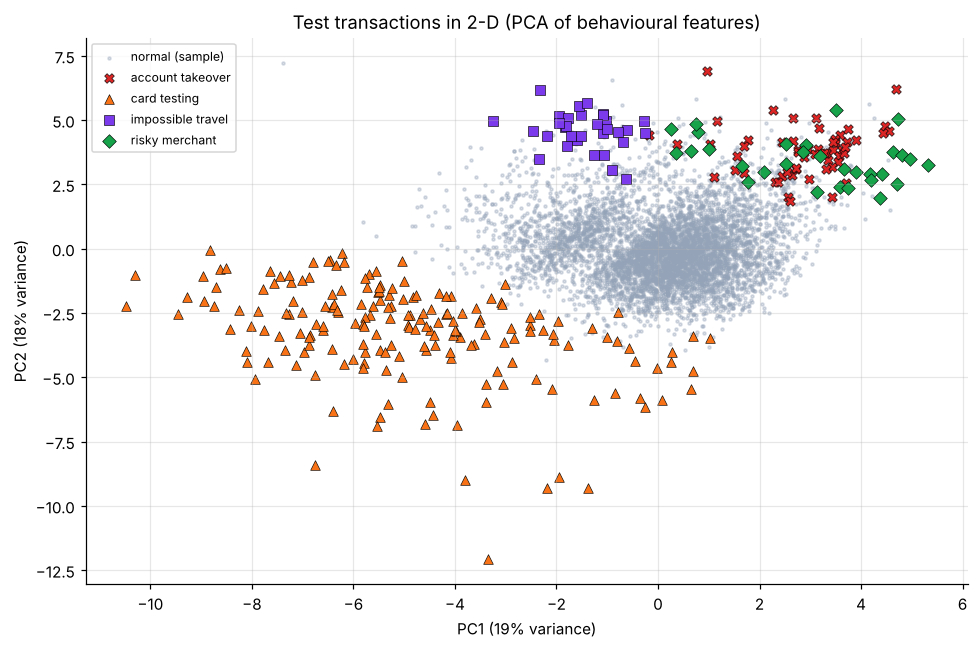

In [11]:
pca = PCA(n_components=2, random_state=SEED).fit(Xtr)
Z = pca.transform(Xte)
fig, ax = plt.subplots(figsize=(9, 6))
norm = test.is_fraud.values == 0
samp = rng.choice(np.where(norm)[0], 6000, replace=False)
ax.scatter(Z[samp, 0], Z[samp, 1], s=4, c="#94a3b8", alpha=.35, label="normal (sample)")
markers = {"account_takeover": ("#dc2626", "X"), "card_testing": ("#f97316", "^"), "impossible_travel": ("#7c3aed", "s"), "risky_merchant": ("#16a34a", "D")}
for t, (c, m) in markers.items():
    sel = test.fraud_type.values == t
    ax.scatter(Z[sel, 0], Z[sel, 1], s=40, c=c, marker=m, edgecolor="k", lw=.4, label=t.replace("_", " "))
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variance)"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variance)")
ax.set_title("Test transactions in 2-D (PCA of behavioural features)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/pca_anomalies.png", bbox_inches="tight"); plt.show()

## 6. Explaining an alert
Analysts need to know **why** a transaction was flagged. For the top alerts of the ensemble, we show which standardised features deviate most from normal behaviour.

In [12]:
ens = scores["Ensemble (rank average)"]
top = np.argsort(-ens)[:8]
expl = []
for i in top:
    zrow = pd.Series(Xte[i], index=FEATURES)
    reasons = ", ".join(f"{k} ({v:+.1f}σ)" for k, v in zrow.reindex(zrow.abs().sort_values(ascending=False).index).head(3).items())
    r = test.iloc[i]
    expl.append({"customer": r.customer_id, "time": r.timestamp.strftime("%d-%b %H:%M"), "amount_inr": round(r.amount_inr), "category": r.merchant_category,
                 "city": r.city, "actual": r.fraud_type, "top reasons": reasons})
display(pd.DataFrame(expl))

,customer,time,amount_inr,category,city,actual,top reasons
0,58,18-Aug 20:55,1193,travel,Kolkata,normal,"tx_last_hour (+12.7σ), log_km_from_home (+6.3σ..."
1,260,19-Aug 04:33,22604,online_retail,Bengaluru,account_takeover,"log_km_from_home (+6.6σ), hours_from_usual (+4..."
2,621,14-Aug 02:16,5558,electronics,Madurai,account_takeover,"log_km_from_home (+6.6σ), amount_robust_z (+3...."
3,514,09-Aug 16:23,1609,grocery,Thanjavur,normal,"log_km_from_home (+6.7σ), log_speed (+6.4σ), t..."
4,126,20-Aug 15:03,148,fuel,Kolkata,normal,"log_km_from_home (+6.6σ), log_speed (+6.4σ), t..."
5,621,14-Aug 03:59,6344,electronics,Madurai,account_takeover,"log_km_from_home (+6.6σ), amount_robust_z (+3...."
6,905,06-Aug 01:11,15333,travel,Kolkata,account_takeover,"log_km_from_home (+6.6σ), log_speed (+6.4σ), a..."
7,316,14-Aug 02:09,6095,online_retail,Kolkata,account_takeover,"log_km_from_home (+6.6σ), hours_from_usual (+4..."


## 7. Conclusions
* **The ensemble wins, and the win is real.** The rank-average ensemble has the best PR-AUC (**0.60** against 0.46 for Isolation Forest; the bootstrap 95% CI of the difference excludes 0). Reviewing just the **top 1% of transactions catches 79% of fraud**, and about 1 in 3 alerts is genuine. The random baseline is 0.4%.
* **Detectors are complementary.** Isolation Forest catches 97% of account takeovers and impossible-travel cases but only 3% of risky-merchant spikes. LOF and One-Class SVM are strongest on card-testing bursts. The simple robust z-score on amount catches card testing (unusually *small* amounts) and risky-merchant spikes, but no impossible-travel cases.
* **Assumptions matter (Mahalanobis + χ²).** 6% of test transactions get χ² p < 0.001, where about 0.1% would be expected if the data were Gaussian. The behavioural features are skewed and partly discrete, so the elliptical, χ²-based approach breaks down. It is a useful reminder to check a method's assumptions before trusting its p-values.
* **Averaging can dilute a specialist.** The ensemble catches only 22% of impossible-travel fraud, which Isolation Forest alone catches almost completely. In production, a *max-of-ranks* rule or a dedicated rule (for example, speed above 900 km/h) would cover that gap.
* **Evaluate at the alert budget.** ROC-AUC is 0.96 or higher for almost every method and hides large practical differences. With 0.4% fraud, the business-relevant numbers are precision and recall in the top 0.5–1% of alerts.
* **Limitations & next steps:** the data is simulated, so the absolute numbers depend on the simulator's assumptions. On real data the same pipeline would add merchant risk scores, device and IP features and analyst feedback. Once confirmed alerts exist, a supervised model trained on them could be layered on top of these unsupervised scores.